# 🌲🌲 Random Forest Classifier from Scratch

**Goal:** Combine many independently-trained decision trees to reduce variance and improve generalisation.

---

## 1. Algorithm Intuition

A single decision tree is a **high-variance** model — it reacts strongly to specific training examples. Random Forest reduces this variance using two sources of randomness:

### 1.1 Bagging (Bootstrap Aggregating)
Each tree is trained on a **bootstrap sample** — a random sample of $m$ examples drawn *with replacement* from the training set.

### 1.2 Feature Randomness
At each split, only a random **subset of $k$ features** is considered, where $k = \lfloor \sqrt{n} \rfloor$ is a common default.

### 1.3 Prediction by Majority Vote
Each tree casts one vote, and the class that receives the most votes wins:
$$\hat{y} = \text{mode}\left( \hat{y}_1, \hat{y}_2, \ldots, \hat{y}_T \right)$$

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $T$ (`n_trees`) | number of trees in the forest |
| $k$ (`max_features`) | features sampled per split |
| `max_depth` | max depth of each individual tree |
| `min_samples_split` | min samples needed to split a node |
| Bootstrap | sampling $m$ examples **with replacement** |

---

## 2. Why Does It Work?

If $T$ trees each make independent errors with probability $p < 0.5$, the probability that the majority vote is wrong decreases exponentially with $T$. The **bias stays low** (each tree is still deep and expressive) while **variance decreases** through averaging.


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.random.seed(99)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Data

In [2]:
def make_blobs(n_per_class, centers, std=0.9, seed=99):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for label, center in enumerate(centers):
        pts = rng.normal(loc=center, scale=std, size=(n_per_class, 2))
        X_list.append(pts)
        y_list.append(np.full(n_per_class, label))
    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

centers = [(-3, 0), (0, 3), (3, 0), (0, -3)]
X_all, y_all = make_blobs(n_per_class=100, centers=centers)
print(f"X: {X_all.shape}, Classes: {np.unique(y_all)}")

X: (400, 2), Classes: [0 1 2 3]


## 5. Train / Test Split

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (320, 2), Test: (80, 2)


## 6. Decision Tree Building Blocks

We reuse the same Gini-based tree from the Decision Tree notebook, but add **feature subsampling** at each split.

In [4]:
class TreeNode:
    def __init__(self, feature=None, threshold=None,
                 left=None, right=None, prediction=None):
        self.feature    = feature
        self.threshold  = threshold
        self.left       = left
        self.right      = right
        self.prediction = prediction

def gini_impurity(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probs = counts / len(y)
    return 1.0 - np.sum(probs ** 2)

def information_gain(y_parent, y_left, y_right):
    m  = len(y_parent)
    ml = len(y_left)
    mr = len(y_right)
    if ml == 0 or mr == 0:
        return 0.0
    return gini_impurity(y_parent) \
           - (ml / m) * gini_impurity(y_left) \
           - (mr / m) * gini_impurity(y_right)

In [5]:
def best_split_rf(X, y, max_features, rng):
    """
    Like best_split, but only considers a random subset of `max_features` features.
    This is the core randomisation that decorrelates the trees.
    """
    n_features = X.shape[1]
    # Sample without replacement from all feature indices
    feature_subset = rng.choice(n_features, size=max_features, replace=False)

    best_feature   = None
    best_threshold = None
    best_ig        = -1.0

    for j in feature_subset:
        values     = np.sort(np.unique(X[:, j]))
        thresholds = (values[:-1] + values[1:]) / 2.0

        for t in thresholds:
            left_mask  = X[:, j] <= t
            ig = information_gain(y, y[left_mask], y[~left_mask])
            if ig > best_ig:
                best_ig        = ig
                best_feature   = j
                best_threshold = t

    return best_feature, best_threshold

In [6]:
def build_tree_rf(X, y, depth, max_depth, min_samples_split, max_features, rng):
    """Recursively build one tree in the forest."""
    n_classes = len(np.unique(y))

    if n_classes == 1 or depth >= max_depth or len(y) < min_samples_split:
        return TreeNode(prediction=Counter(y.astype(int)).most_common(1)[0][0])

    feat, thresh = best_split_rf(X, y, max_features, rng)

    if feat is None:
        return TreeNode(prediction=Counter(y.astype(int)).most_common(1)[0][0])

    left_mask  = X[:, feat] <= thresh
    right_mask = ~left_mask

    left_child  = build_tree_rf(X[left_mask],  y[left_mask],
                                depth + 1, max_depth, min_samples_split, max_features, rng)
    right_child = build_tree_rf(X[right_mask], y[right_mask],
                                depth + 1, max_depth, min_samples_split, max_features, rng)

    return TreeNode(feature=feat, threshold=thresh,
                    left=left_child, right=right_child)

def predict_one(node, x):
    if node.prediction is not None:
        return node.prediction
    if x[node.feature] <= node.threshold:
        return predict_one(node.left,  x)
    return predict_one(node.right, x)

def predict_tree(node, X):
    return np.array([predict_one(node, x) for x in X])

## 7. Random Forest: Bootstrap + Build + Vote

In [7]:
def train_random_forest(X, y, n_trees=20, max_depth=6,
                        min_samples_split=5, max_features=None, seed=42):
    """
    Train a Random Forest.

    Parameters
    ----------
    X              : ndarray (m, n)
    y              : ndarray (m,) integer labels
    n_trees        : number of trees
    max_depth      : max depth per tree
    min_samples_split : min samples to split
    max_features   : features considered per split (default: floor(sqrt(n)))
    seed           : base random seed

    Returns
    -------
    trees : list of TreeNode (roots)
    """
    m, n = X.shape
    if max_features is None:
        max_features = max(1, int(np.floor(np.sqrt(n))))

    trees = []
    for t in range(n_trees):
        rng = np.random.default_rng(seed + t)   # different seed per tree

        # Bootstrap sample: sample m indices with replacement
        bootstrap_idx = rng.integers(0, m, size=m)
        X_boot = X[bootstrap_idx]
        y_boot = y[bootstrap_idx]

        tree = build_tree_rf(X_boot, y_boot,
                             depth=0, max_depth=max_depth,
                             min_samples_split=min_samples_split,
                             max_features=max_features,
                             rng=rng)
        trees.append(tree)
        if (t + 1) % 5 == 0:
            print(f"  Trained tree {t + 1}/{n_trees}")

    return trees

In [8]:
def predict_forest(trees, X):
    """
    Majority vote over all trees.

    Returns
    -------
    predictions : ndarray (m,)
    """
    # all_preds shape: (n_trees, m)
    all_preds = np.array([predict_tree(tree, X) for tree in trees])

    # For each sample, take majority vote across trees
    predictions = []
    for sample_votes in all_preds.T:            # iterate over m samples
        vote = Counter(sample_votes.astype(int)).most_common(1)[0][0]
        predictions.append(vote)
    return np.array(predictions)

## 8. Train the Forest

In [9]:
print("Training Random Forest (20 trees)...")
trees = train_random_forest(X_train, y_train.astype(int),
                            n_trees=20, max_depth=6,
                            min_samples_split=5, seed=42)
print("Done.")

Training Random Forest (20 trees)...
  Trained tree 5/20


  Trained tree 10/20
  Trained tree 15/20


  Trained tree 20/20
Done.


## 9. Decision Boundary Visualisation

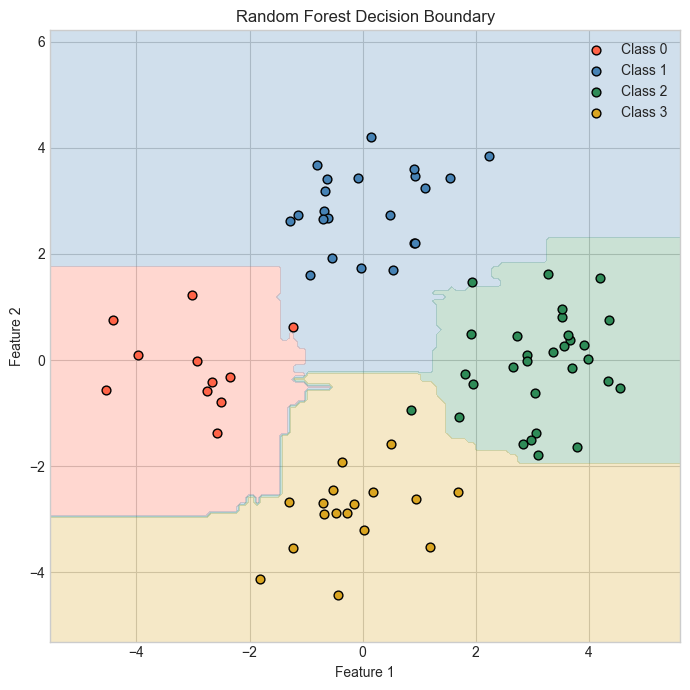

In [10]:
palette = ['tomato', 'steelblue', 'seagreen', 'goldenrod']

x1_min, x1_max = X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5
x2_min, x2_max = X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 150),
                     np.linspace(x2_min, x2_max, 150))
grid       = np.c_[xx.ravel(), yy.ravel()]
grid_preds = predict_forest(trees, grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 7))
ax.contourf(xx, yy, grid_preds,
            levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
            colors=palette, alpha=0.25)
for cls in range(4):
    mask = y_test.astype(int) == cls
    ax.scatter(X_test[mask, 0], X_test[mask, 1],
               color=palette[cls], edgecolors='k', s=40, label=f'Class {cls}')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_title('Random Forest Decision Boundary')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Evaluation Metrics

In [11]:
def accuracy(y_true, y_pred):
    return np.mean(y_true.astype(int) == y_pred.astype(int))

y_pred_train = predict_forest(trees, X_train)
y_pred_test  = predict_forest(trees, X_test)

print(f"Train Accuracy: {accuracy(y_train, y_pred_train):.4f}")
print(f"Test  Accuracy: {accuracy(y_test,  y_pred_test):.4f}")

Train Accuracy: 0.9969
Test  Accuracy: 0.9625


## 11. Accuracy vs. Number of Trees

  Trained tree 5/50


  Trained tree 10/50


  Trained tree 15/50


  Trained tree 20/50


  Trained tree 25/50


  Trained tree 30/50


  Trained tree 35/50


  Trained tree 40/50


  Trained tree 45/50


  Trained tree 50/50
  Trees=  1 → Test Accuracy=0.9500
  Trees=  2 → Test Accuracy=0.9500
  Trees=  5 → Test Accuracy=0.9375
  Trees= 10 → Test Accuracy=0.9625
  Trees= 15 → Test Accuracy=0.9750
  Trees= 20 → Test Accuracy=0.9750
  Trees= 30 → Test Accuracy=0.9750
  Trees= 50 → Test Accuracy=0.9750


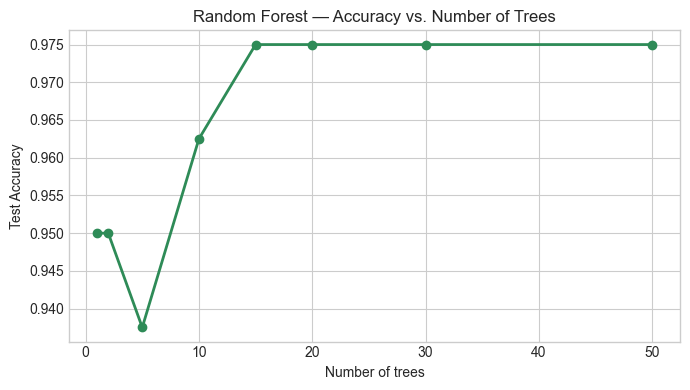

In [12]:
n_tree_values = [1, 2, 5, 10, 15, 20, 30, 50]
test_accs     = []

# Train a large forest once and measure cumulative accuracy
big_forest = train_random_forest(X_train, y_train.astype(int),
                                 n_trees=50, max_depth=6, seed=0)
for t in n_tree_values:
    acc = accuracy(y_test, predict_forest(big_forest[:t], X_test))
    test_accs.append(acc)
    print(f"  Trees={t:3d} → Test Accuracy={acc:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(n_tree_values, test_accs, marker='o', color='seagreen', linewidth=2)
plt.xlabel('Number of trees')
plt.ylabel('Test Accuracy')
plt.title('Random Forest — Accuracy vs. Number of Trees')
plt.tight_layout()
plt.show()

## 12. Observations and Limitations

### What we observed
- Test accuracy improves as we add more trees, then plateaus — more trees never hurt, but the marginal gain diminishes.
- The decision boundary is smoother than a single tree because the majority vote averages out individual quirks.
- Training accuracy is high but test accuracy is also strong — significantly less overfitting than a single deep tree.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Slow prediction** | Must run every query through $T$ trees. |
| **Memory** | Storing $T$ full trees can be large. |
| **Interpretability** | Unlike a single tree, a forest is hard to visualise or explain. |
| **Still axis-aligned** | Individual trees only make horizontal/vertical cuts. |
| **Not great for regression** | Our implementation is classification-only; averaging predictions for regression is a straightforward extension. |
